In [1]:
# ===============================================================_
# ITELv5_04_PREPROCESAMIENTO
# ===============================================================_

# 4.0 — Cargar configuración global
%run "./ITELv5_01_CONFIGURACION.ipynb"
print("✅ Configuración global cargada (ITELv5)\n")

import librosa, soundfile as sf
import numpy as np, pandas as pd
from pathlib import Path
from scipy.signal import butter, filtfilt
from tqdm import tqdm

c:\Users\USER\Documents\GitHub\ITEL\.venv\Lib\site-packages\nbformat\__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


BASE_DIR      : C:\Users\USER\Documents\GitHub\ITEL\research
DATA_DIR      : C:\Users\USER\Documents\GitHub\ITEL\research\Datos_Brutos
PROCESADOS_DIR: C:\Users\USER\Documents\GitHub\ITEL\research\processed_data
MODELS_DIR    : C:\Users\USER\Documents\GitHub\ITEL\assets\models
EMB_DIM       : 6144
Rutas Principales de ITELv5:
  Datos_Brutos:     C:\Users\USER\Documents\GitHub\ITEL\research\Datos_Brutos
  Datos Procesados: C:\Users\USER\Documents\GitHub\ITEL\research\processed_data
  Modelos:          C:\Users\USER\Documents\GitHub\ITEL\assets\models
  Reportes:         C:\Users\USER\Documents\GitHub\ITEL\research\reports
  Reportes (CSV):   C:\Users\USER\Documents\GitHub\ITEL\research\reports\CSV
  Reportes (Figuras): C:\Users\USER\Documents\GitHub\ITEL\research\reports\Figuras
  Logs:             C:\Users\USER\Documents\GitHub\ITEL\research\logs

Rutas vocales detectadas:
  Healthy con 308 subrutas de vocales
  Patients con 378 subrutas de vocales

Configuracion ITELv5 lista.
Verifican

In [2]:
# ===============================================================_
# 4.1 — Parámetros de preprocesamiento
# ===============================================================_

TARGET_SR = 16000        # Frecuencia de muestreo final
HP_CUTOFF = 100          # Filtro pasa-altas
TARGET_DURATION = 2.0    # Duración en segundos

In [3]:
# ===============================================================_
# 4.2 — Funciones de procesamiento
# ===============================================================_

def highpass_filter(y, sr, cutoff=HP_CUTOFF, order=5):
    b, a = butter(order, cutoff / (0.5 * sr), btype='high', analog=False)
    return filtfilt(b, a, y)

def ajustar_duracion(y, sr, target_dur=TARGET_DURATION):
    target_len = int(sr * target_dur)
    if len(y) > target_len:
        start = (len(y) - target_len) // 2
        y = y[start:start + target_len]
    else:
        pad = (target_len - len(y)) // 2
        y = np.pad(y, (pad, target_len - len(y) - pad))
    return y

def procesar_audio(ruta, sr_objetivo=TARGET_SR):
    try:
        y, sr = librosa.load(ruta, sr=None, mono=True)
        if sr != sr_objetivo:
            y = librosa.resample(y, orig_sr=sr, target_sr=sr_objetivo)
            sr = sr_objetivo
        y = highpass_filter(y, sr, cutoff=HP_CUTOFF)
        y = y / np.max(np.abs(y)) if np.max(np.abs(y)) > 0 else y
        y = ajustar_duracion(y, sr)
        return y, sr, 'OK'
    except Exception as e:
        return None, None, f'Error: {e}'

In [4]:
# ===============================================================_
# 4.3 — Cargar listado de audios desde gestión de contenido (v5)
# ===============================================================_

# Esta ruta ahora apunta a Reportes/CSV/
csv_path = ITELConfig.CSV_DIR / 'gestion_contenido_v5.csv'

if csv_path.exists():
    print(f'📄 Cargando listado desde {csv_path} ...')
    df_audios = pd.read_csv(csv_path)
else:
    raise FileNotFoundError(f"{csv_path} no existe. Ejecuta primero ITELv5_03_GESTION_CONTENIDO.ipynb")

print(f'✅ {len(df_audios)} audios listos para procesar.')
display(df_audios.head())

📄 Cargando listado desde C:\Users\USER\Documents\GitHub\ITEL\research\reports\CSV\gestion_contenido_v5.csv ...
✅ 3730 audios listos para procesar.


,categoria,subcarpeta,tipo,silabas,etiqueta,nombre,ruta
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...


In [5]:
# ===============================================================_
# 4.4 — Procesamiento de audios
# ===============================================================_

procesados = []
print('\n🎧 Iniciando preprocesamiento de audios...\n')
for _, row in tqdm(df_audios.iterrows(), total=len(df_audios), desc='Procesando'):
    ruta = Path(row['ruta'])
    if not ruta.exists():
        continue
    y, sr, estado = procesar_audio(ruta)
    procesados.append({
        'categoria': row.get('categoria'),
        'subcarpeta': row.get('subcarpeta'),
        'tipo': row.get('tipo'),
        'silabas': row.get('silabas'),
        'etiqueta': row.get('etiqueta'),
        'nombre': row.get('nombre'),
        'ruta': str(ruta),
        'sr_final': sr,
        'estado': estado,
        'duracion_s': (len(y)/sr) if (y is not None and sr) else None
    })

df_pre = pd.DataFrame(procesados)
display(df_pre.head())


🎧 Iniciando preprocesamiento de audios...



Procesando: 100%|██████████| 3730/3730 [00:04<00:00, 746.45it/s] 


,categoria,subcarpeta,tipo,silabas,etiqueta,nombre,ruta,sr_final,estado,duracion_s
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...,16000,OK,2.0
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...,16000,OK,2.0
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...,16000,OK,2.0
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...,16000,OK,2.0
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...,16000,OK,2.0


In [6]:
# ===============================================================_
# 4.5 — Resumen y exportación
# ===============================================================_

print('\n📊 Resumen de procesamiento:')
display(df_pre['estado'].value_counts())

# Esta ruta ahora apunta a Reportes/CSV/
output_path = ITELConfig.CSV_DIR / 'preprocesamiento_resumen_v5.csv'
df_pre.to_csv(output_path, index=False)
print(f'\n💾 Resumen exportado a: {output_path}')


📊 Resumen de procesamiento:


estado
OK    3730
Name: count, dtype: int64


💾 Resumen exportado a: C:\Users\USER\Documents\GitHub\ITEL\research\reports\CSV\preprocesamiento_resumen_v5.csv



🎙️ Ejemplo de preprocesamiento: C:\Users\USER\Documents\GitHub\ITEL\research\Datos_Brutos\Patients\P50\03_1SL\4zm3nos.wav
💾 Gráfico de onda guardado en C:\Users\USER\Documents\GitHub\ITEL\research\reports\Figuras\onda_preprocesamiento_v5.png


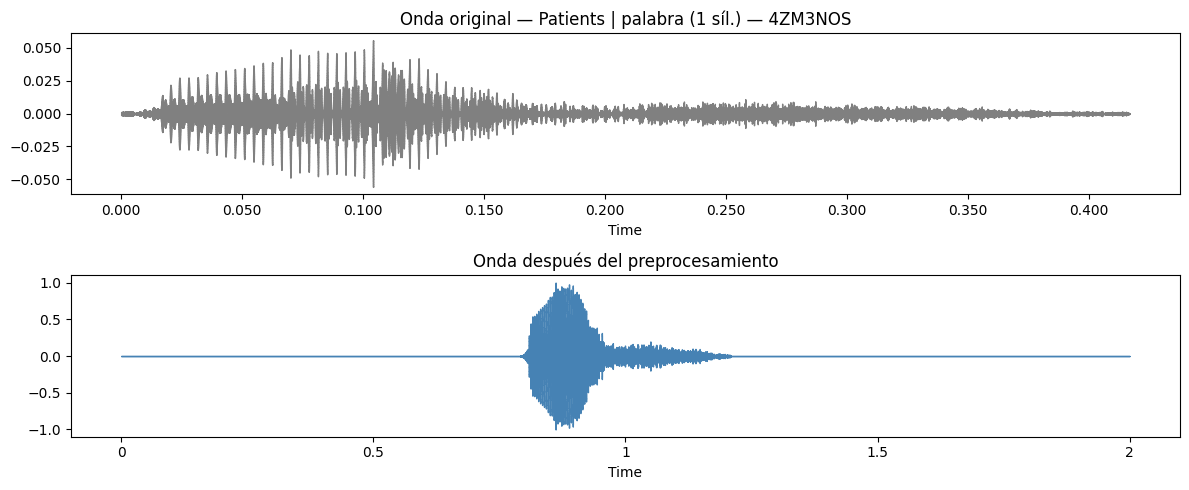

In [7]:
# ===============================================================_
# 4.6 — Visualización de ejemplo (onda antes y después)
# ===============================================================_
import matplotlib.pyplot as plt, librosa.display
import random # Asegúrate de que random esté importado

ejemplo = df_audios.sample(1).iloc[0] if len(df_audios)>0 else None
if ejemplo is not None:
    ruta = ejemplo['ruta']
    print(f'\n🎙️ Ejemplo de preprocesamiento: {ruta}')
    y_orig, sr_orig = librosa.load(ruta, sr=None)
    y_proc, sr_proc, _ = procesar_audio(ruta)
    plt.figure(figsize=(12,5))
    plt.subplot(2,1,1)
    librosa.display.waveshow(y_orig, sr=sr_orig, color='gray')
    titulo1 = f"Onda original — {ejemplo.get('categoria')} | {ejemplo.get('tipo')}"
    if pd.notna(ejemplo.get('silabas')):
        titulo1 += f" ({int(ejemplo.get('silabas'))} síl.)"
    if pd.notna(ejemplo.get('etiqueta')):
        titulo1 += f" — {str(ejemplo.get('etiqueta')).upper()}"
    plt.title(titulo1)
    plt.subplot(2,1,2)
    librosa.display.waveshow(y_proc, sr=sr_proc, color='steelblue')
    plt.title('Onda después del preprocesamiento')
    plt.tight_layout()
    
    # --- Cambio de Ruta ---
    # Guardar en Reportes/Figuras/
    save_path_fig = ITELConfig.FIGURAS_DIR / 'onda_preprocesamiento_v5.png'
    plt.savefig(save_path_fig, dpi=300)
    print(f"💾 Gráfico de onda guardado en {save_path_fig}")
    plt.show()
else:
    print('⚠️ Sin ejemplos disponibles para graficar.')

In [8]:
# ===============================================================_
# 4.7 — Limpieza final
# ===============================================================_
import gc, torch
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print('\n✅ Sección 4 (v5) completada. Listo para extracción de embeddings (Sección 5).')


✅ Sección 4 (v5) completada. Listo para extracción de embeddings (Sección 5).
